
=== CONVERGENCE PERFORMANCE DATA ===
Step Size (h)   | Euler Approx (t=2)   | Exact Value (t=2)  | Absolute Error 
---------------------------------------------------------------------------
0.2             | 10.205253            | 16.167168          | 5.961915       
0.1             | 12.646560            | 16.167168          | 3.520609       
0.05            | 14.233190            | 16.167168          | 1.933978       
0.02            | 15.345157            | 16.167168          | 0.822012       
0.01            | 15.747429            | 16.167168          | 0.419740       
0.005           | 15.955047            | 16.167168          | 0.212121       
---------------------------------------------------------------------------


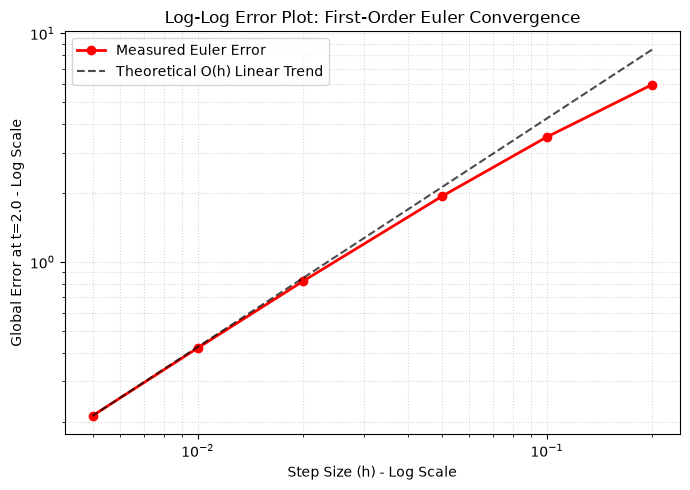

In [2]:
# THIS CELL EVALUATES THE FUNCTION USING EULER'S METHOD AND PLOTS ERROR VS H

import numpy as np
import matplotlib.pyplot as plt

def euler_method(f, t0, tend, y0, h):
    """Solves the ODE dy/dt = f(t, y) using the Explicit Euler Method."""
    num_steps = int(np.round((tend - t0) / h))
    t_values = np.linspace(t0, tend, num_steps + 1)
    y_values = np.zeros(num_steps + 1)
    y_values[0] = y0
    
    for n in range(num_steps):
        # Explicit Euler Step
        y_values[n+1] = y_values[n] + h * f(t_values[n], y_values[n])
        
    return t_values, y_values

# 1. Setup specific problem properties: y' = t*y + t^3
def my_ode(t, y):
    return t * y + t**3

# Analytical exact solution for y(0) = 1
def exact_solution(t):
    return 3 * np.exp(0.5 * t**2) - t**2 - 2

# Parameters
t_start = 0.0
t_end = 2.0
y_start = 1.0  # y(0) = 1
exact_final_y = exact_solution(t_end)

# Step size variations to calculate
h_values = [0.2, 0.1, 0.05, 0.02, 0.01, 0.005]
errors = []

# 2. Print the Output Table Header using native string alignment
print("\n=== CONVERGENCE PERFORMANCE DATA ===")
print(f"{'Step Size (h)':<15} | {'Euler Approx (t=2)':<20} | {'Exact Value (t=2)':<18} | {'Absolute Error':<15}")
print("-" * 75)

# 3. Iterate through h choices to harvest metrics and print table rows
for h in h_values:
    t_approx, y_approx = euler_method(my_ode, t_start, t_end, y_start, h)
    final_approx = y_approx[-1]
    global_error = abs(exact_final_y - final_approx)
    errors.append(global_error)
    
    # Print row with fixed-width spacing
    print(f"{h:<15} | {final_approx:<20.6f} | {exact_final_y:<18.6f} | {global_error:<15.6f}")

print("-" * 75)

# 4. Generate the Log-Log Plot
plt.figure(figsize=(7, 5))
plt.loglog(h_values, errors, 'ro-', linewidth=2, label='Measured Euler Error')

# Overlay theoretical linear O(h) trend slope for comparison reference
theoretical_trend = [errors[-1] * (h / h_values[-1]) for h in h_values]
plt.loglog(h_values, theoretical_trend, 'k--', alpha=0.7, label='Theoretical O(h) Linear Trend')

# Visual configurations
plt.xlabel('Step Size (h) - Log Scale')
plt.ylabel('Global Error at t=2.0 - Log Scale')
plt.title("Log-Log Error Plot: First-Order Euler Convergence")
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


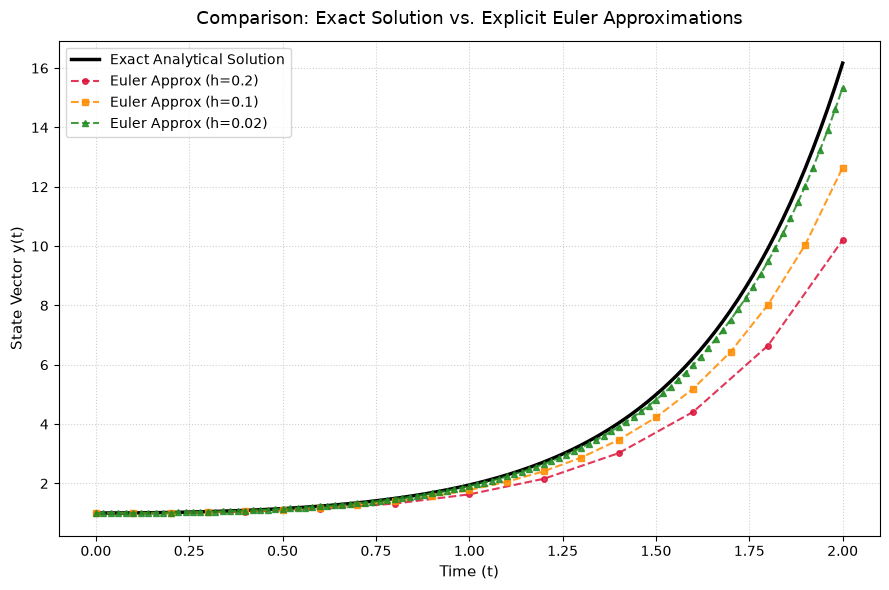

In [6]:
# THIS CELL PLOTS THE EXACT SOLUTION AND EULER APPROXIMATIONS ON A SINGLE GRAPH

import numpy as np
import matplotlib.pyplot as plt

# --- Re-declaring dependencies to avoid NameErrors ---
def euler_method(f, t0, tend, y0, h):
    num_steps = int(np.round((tend - t0) / h))
    t_values = np.linspace(t0, tend, num_steps + 1)
    y_values = np.zeros(num_steps + 1)
    y_values[0] = y0
    for n in range(num_steps):
        y_values[n+1] = y_values[n] + h * f(t_values[n], y_values[n])
    return t_values, y_values

def my_ode(t, y):
    return t * y + t**3

def exact_solution(t):
    return 3 * np.exp(0.5 * t**2) - t**2 - 2

t_start = 0.0
t_end = 2.0
y_start = 1.0
# ----------------------------------------------------

# 1. Generate fine mesh data for a smooth exact solution reference curve
t_fine = np.linspace(t_start, t_end, 200)
y_exact = exact_solution(t_fine)

plt.figure(figsize=(9, 6))

# 2. Plot the exact analytical solution as the primary baseline line
plt.plot(t_fine, y_exact, color='black', linewidth=2.5, label='Exact Analytical Solution')

# 3. Superimpose chosen step sizes from your list to showcase convergence visually
sample_h_values = [0.2, 0.1, 0.02]
colors = ['crimson', 'darkorange', 'forestgreen']
markers = ['o', 's', '^'] 

for h, color, marker in zip(sample_h_values, colors, markers):
    t_approx, y_approx = euler_method(my_ode, t_start, t_end, y_start, h)
    plt.plot(t_approx, y_approx, linestyle='--', marker=marker, color=color, 
             markersize=4, alpha=0.85, label=f'Euler Approx (h={h})')

# 4. Visual configuration and labeling
plt.title("Comparison: Exact Solution vs. Explicit Euler Approximations", fontsize=13, pad=12)
plt.xlabel("Time (t)", fontsize=11)
plt.ylabel("State Vector y(t)", fontsize=11)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()



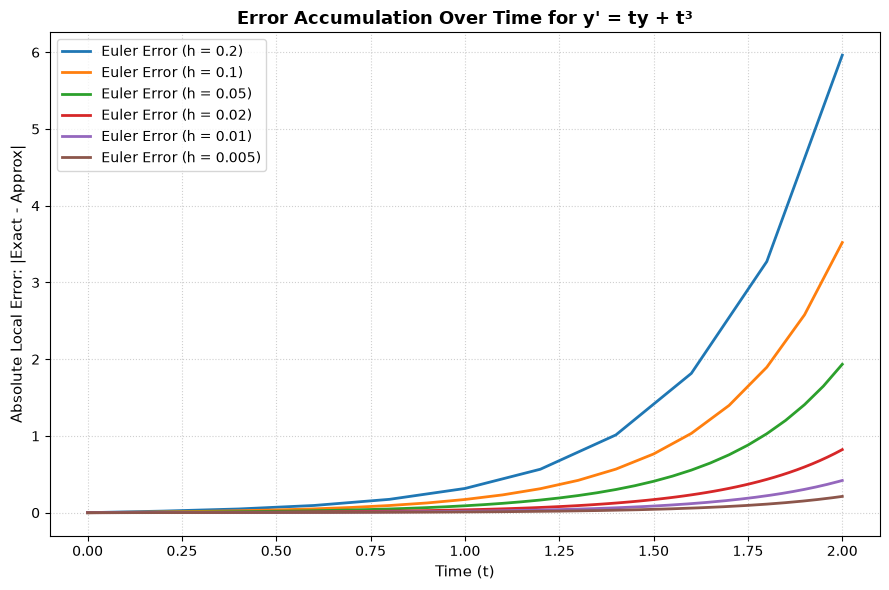

In [3]:
# THIS CELL PLOTS ERROR VS TIME FOR THIS FUNCTION

plt.figure(figsize=(9, 6))

# Analyze how error grows over time for each step size
for h in h_values:
    # 1. Run Euler method to get arrays across time
    t_arr, y_approx_arr = euler_method(my_ode, t_start, t_end, y_start, h)
    
    # 2. Compute the exact solution at every corresponding timestamp
    y_exact_arr = exact_solution(t_arr)
    
    # 3. Calculate step-by-step absolute error tracking array
    error_over_time = np.abs(y_exact_arr - y_approx_arr)
    
    # 4. Plot error accumulation curve over time
    plt.plot(t_arr, error_over_time, label=f'Euler Error (h = {h})', linewidth=2)

# Chart layout styling
plt.xlabel('Time (t)', fontsize=11)
plt.ylabel('Absolute Local Error: |Exact - Approx|', fontsize=11)
plt.title("Error Accumulation Over Time for y' = ty + t³", fontsize=13, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


Step Size (h)   | Empirical Error    | Theoretical Bound    | Safety Check
------------------------------------------------------------------------
0.2             | 5.961915           | 294.789825           | PASSED      
0.1             | 3.520609           | 147.394913           | PASSED      
0.05            | 1.933978           | 73.697456            | PASSED      
0.02            | 0.822012           | 29.478983            | PASSED      
0.01            | 0.419740           | 14.739491            | PASSED      
0.005           | 0.212121           | 7.369746             | PASSED      


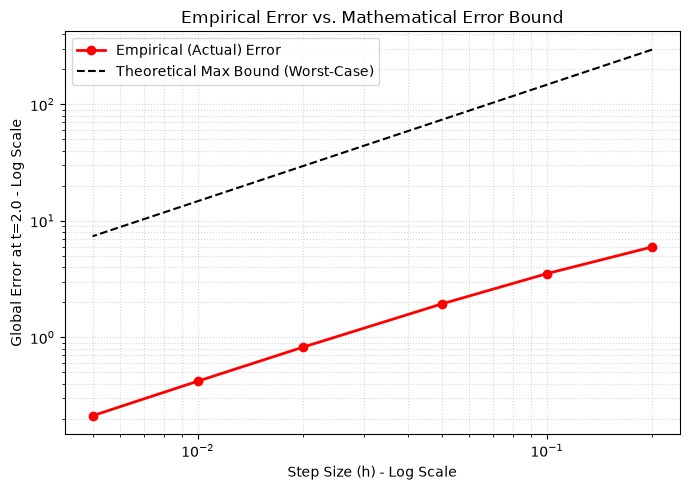

In [ ]:
#THIS CELL COMPARES EMPIRICAL VS THEORETICAL ERROR BOUNDS FOR THE FUNCTION (must run other cells first)

# Theoretical constants derived for y' = ty + t^3 on t in [0,2]
L = 2.0   # Lipschitz constant (max of df/dy = t)
M = 110.0 # Upper bound of |y''(t)| on the interval

# Calculate the Dahlquist multiplier factor: (M / 2L) * (e^(L*(T-t0)) - 1)
T_total = t_end - t_start
theoretical_multiplier = (M / (2 * L)) * (np.exp(L * T_total) - 1)

print(f"{'Step Size (h)':<15} | {'Empirical Error':<18} | {'Theoretical Bound':<20} | {'Safety Check':<12}")
print("-" * 72)

theoretical_bounds = []

for h, emp_error in zip(h_values, errors):
    # Compute the worst-case theoretical maximum error for this specific h
    th_bound = theoretical_multiplier * h
    theoretical_bounds.append(th_bound)
    
    # Verify empirical error behaves safely below the theoretical bound
    is_safe = "PASSED" if emp_error <= th_bound else "FAILED"
    
    print(f"{h:<15} | {emp_error:<18.6f} | {th_bound:<20.6f} | {is_safe:<12}")

# --- Plot the comparison ---
plt.figure(figsize=(7, 5))
plt.loglog(h_values, errors, 'ro-', linewidth=2, label='Empirical (Actual) Error')
plt.loglog(h_values, theoretical_bounds, 'k--', linewidth=1.5, label='Theoretical Max Bound (Worst-Case)')

plt.xlabel('Step Size (h) - Log Scale')
plt.ylabel('Global Error at t=2.0 - Log Scale')
plt.title("Empirical Error vs. Mathematical Error Bound")
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
